# 0. 용어정리

1. 픽셀 : 이미지 데이터를 구성하는 가장 기본적인 단위
2. 채널 : 이미지의 색상 정보를 구성하는 각각의 데이터 층
3. 색공강 : 이미지를 구성하는 색상을 숫자로 표현하는 방법이나 체계

# 1. CNN의 개념

- 등장배경: 컴퓨터는 이미지를 픽셀이 모여서 만들어진 숫자 데이터로 인식함. <br>이때, <u>이미지를 단순히 1차원 배열로 펼쳐서 학습하면(MLP방식) 원래 이미지가 가지고 있던 2차원 공간 구조가 명확하게 활용되지 않음</u> <br>-> 학습이 어려워짐

- **CNN은 이미지의 공간적 특징을 유지하면서 Conv와 Pool을 반복하여 이미지의 특징을 추출** <br>-> 이후 flatten을 통해 이미지 특징을 1차원으로 변환하고, FC Layer를 적용하여 이미지를 분류함. 
    - FC Layer(fully connected layer)란?:딥러닝에서 한 층의 모든 뉴런이 다음 층의 모든 뉴런과 빠짐없이 연결되어 있는 기본 신경망 구조

-  CNN의 기본적인 구조
    1. Convolution Layer: 이미지 특징 추출
    2. Pooling : 특징 맵의 크기 축소
    3. Flatten : 다차원 데이터를 1차원으로 축소
    4. Fully Connected Layer : 추출된 특징을 바탕으로 이미지가 어떤 클래스에 속하는지 분류

- 특징 추출이란? 
    - Convolution Layer -> **필터(Kernel)을 이미지 위에서 이동시키며** 이미지의 특징을 추출 
    - Pooling -> 추출된 특징 맵의 크기를 줄이고 중요한 특징을 유지하여 연산량을 감소시킴

**Conv + Pool 을 반복하여 이미지의 공간적인 특징을 추출한 후 FC Layer를 통해 분류한다는 점이 CNN의 핵심 구조이다.**

# 2. MLP vs CNN
- 이미지 구조를 유지하는 모델이 필요한 이유: 일반적인 데이터는 각 열이 독립적인 의미를 가진 값들이 나열된 형태임<br>반면, **이미지는 픽셀들이 가로와 세로 방향으로 연결되어 있으며, 주변 픽셀 간의 관계와 위치 정보가 중요함**

<br>-> **픽셀 간의 공간적 관계와 이미지 구조를 유지하면서 특징을 학습할 수 있는 모델이 필요함**

- MLP의 한계 1: 학습데이터에서 보지 못한 위치나 형태의 변화가 발생하면 기존의 숫자로 인식하지 못함.
- CNN : 특정한 특징이 정확히 어느 픽셀에 있는지만 보는 것을 넘어, **이미지 안에 해당 특징이 존재하는 지를 효과적으로 학습가능**

- MLP의 한계 2: MLP의 경우, 완전 연결구조로 인해 파라미터가 급증 -> 과적합 가능성이 상승하고 이미지가 클 수록 학습이 느려짐
- CNN : 일정 부분만 필터를 적용하는 **부분 연결 구조**를 사용함. 예) 3*3 필터면 주변 9픽셀의 특징만 추출함<br>이미지 크기가 커도 필터 의 크기와 개수만 일정하면 파라미터가 급증하지 않음

- MLP의 한계3 : 이미지를 1차원 배열로 flatten하는 과정에서 **원래 이미지에서 어떤 픽셀이 가까이 있었는지에 대한 2차원 공간 구조가 명시적으로 유지되지 않음 <br> -> 정보 공간 손실**
- CNN : 이미지를 입력받을 때 H*W*C 형태의 다차원 구조를 유지한 상태로 처리함. 또한 이미지의 공간적 특징을 먼저 학습한 후 Flatten을 진행 <br> 픽셀의 위치 관계와 주변 영역의 특징을 활용하는 데 유리

# 3. 합성곱과 풀링

##### Convolution Layer 연산과정

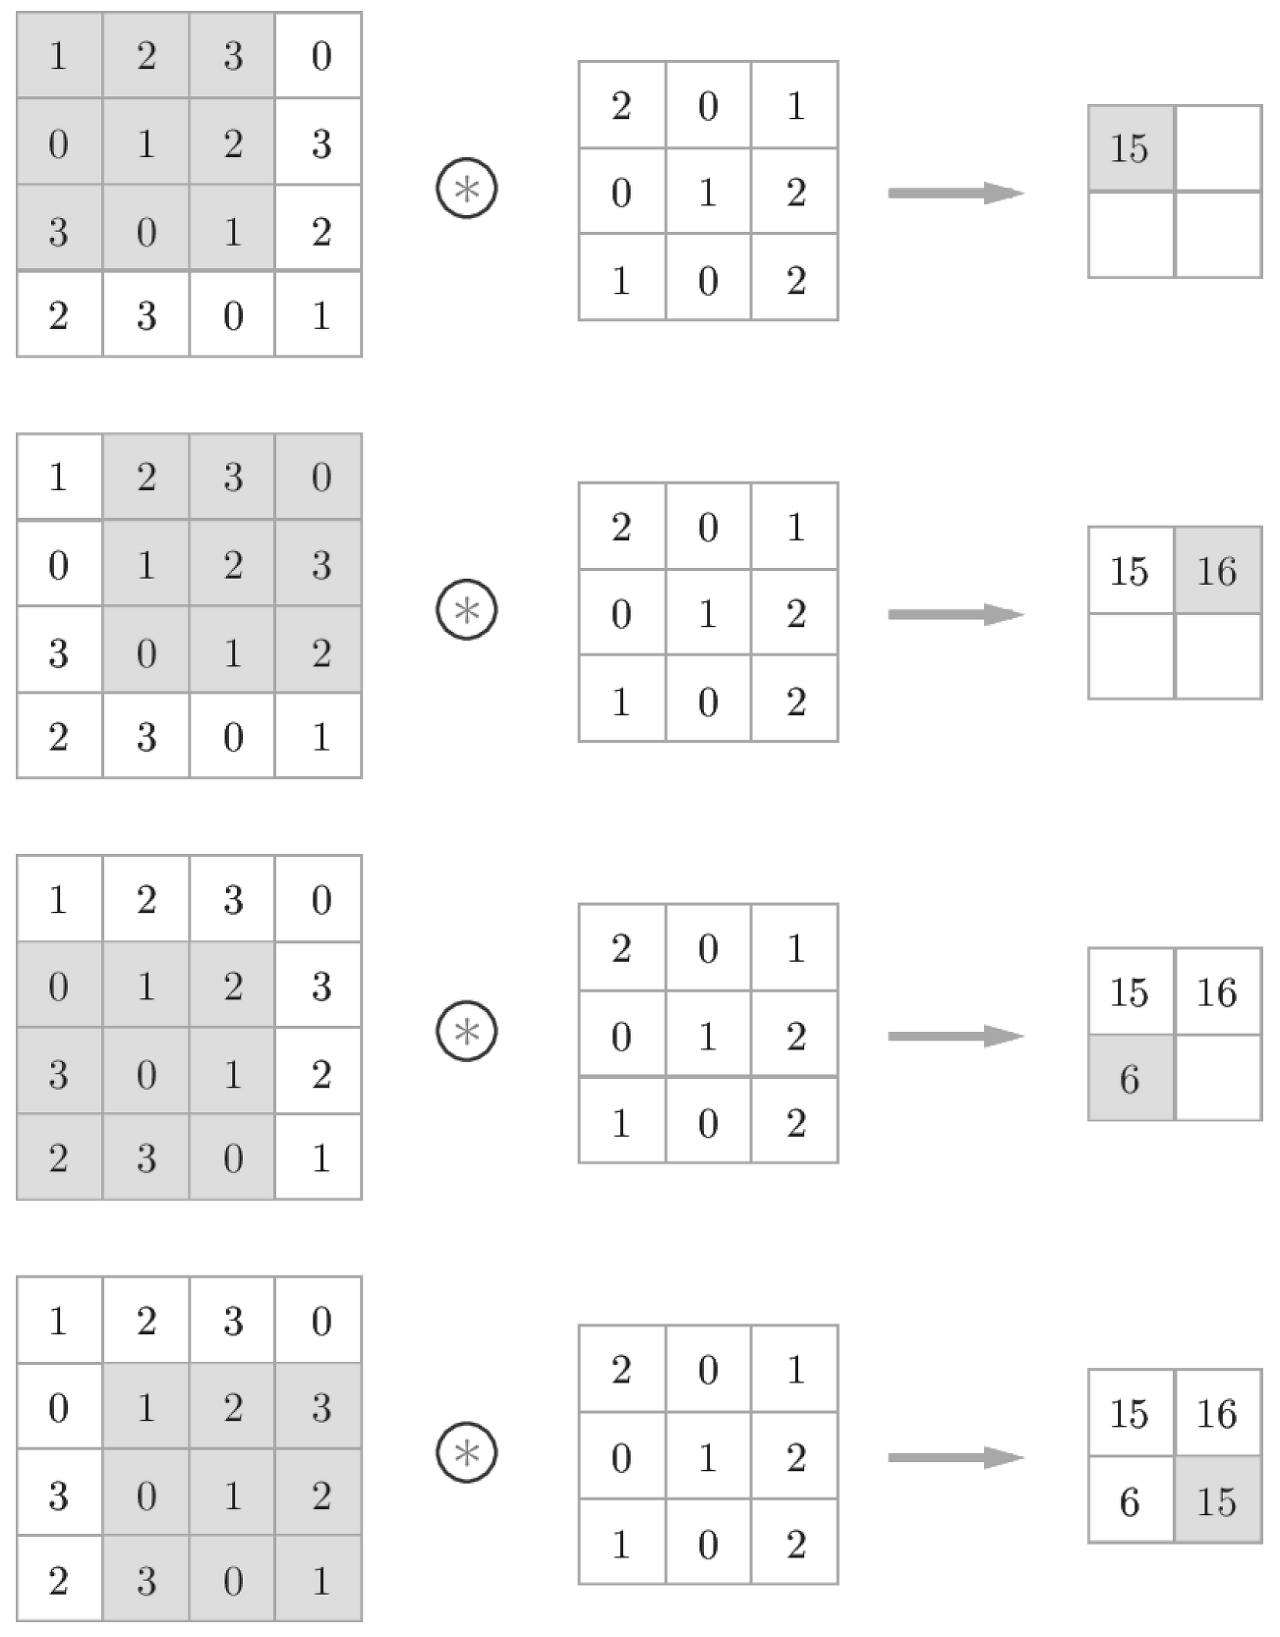

**1. 필터가 이미지 위를 슬라이딩**

    - 작은 크기의 필터를 입력 이미지의 왼쪽 위에 배치
    - 이후 정해진 간격만큼 오른쪽으로 이동하면서 이미지의 각 영역을 차례대로 확인
    - 한 행의 연산이 끝나면 다음 행으로 이동하여 같은 과정을 반복

**2. 각 위치에서 요소별 곱셈 후 합계 계산**

    - 필터가 위치한 영역의 픽셀 값과 필터의 가중치를 각각 같은 위치끼리 곱함
    - 곱한 결과를 모두 더하여 하나의 숫자를 계산

**3. 결과를 Feature Map에 저장**

    - 한 위치에서 계산된 결과값을 Feature Map의 해당 위치에 저장
    - 필터가 모든 위치에서 연산을 마치면 하나의 Feature Map이 완성

예시) (1\*2+2\*0+3\*1)+(0\*0+1\*1+2\*2)+(3**1+0\*0+1*2)=15

##### Feature Map
- Convolution 연산을 통해 생성되는 결과 데이터
- 필터가 이미지의 여러 위치에서 계산한 결과값을 모아 하나의 Feature Map을 구성
- 필터가 특정 특징에 반응할수록 해당 위치의 Feature Map 값이 커짐

- Feature Map 개수는 사용하는 필터의 개수에 따라 결정됨. 예) 3*32*32 이미지에 3*5*5 필터를 적용하면 featuremap은 6개 생성됨

##### Padding
- 개념: Convolution 연산을 수행하기 전에 입력 이미지의 가장자리에 추가적인 픽셀을 삽입하는 것
- 일반적으로 가장자리에 0을 추가하는 Zero-Padding을 많이 사용함.
- 사용 이유: 이미지 크기가 연산으로 인해 지나치게 작아지는 것을 방지해줌 + 이미지 가장자리의 픽셀 또한 필터 연산에 충분히 포함되어 학습됨

##### Stride(보폭)
- 필터가 움직이는 보폭
- 보폭이 크면, Feature Map이 작아지고 보폭이 작으면 Feature Map이 커짐
- Stride는 특징을 얼마나 세밀하게 추출할지와 연산 효율을 어떻게 조절할지 결정하는 요소

##### Pooling
- 개념 : Feature Map의 크기를 줄이는 연산
- 이미지의 작은 위치 변화에 대한 민감도를 낮춰 모델이 특징을 더 안정적으로 인식할 수 있도록 도와줌
- 연산 방식: 일정한 크기의 영역을 설정하고, 해당 영역에 포함된 값들을 하나의 값으로 요약함
- 종류
    - Max Pooling: 지정된 영역에서 가장 큰 값을 선택하는 방식
    - Average Pooling : 지정된 영역 안에 있는 모든 값의 평균을 계산하는 방식

- 장점
    - 차원 축소로 계산량 감소
    - 위치 변화에 대한 강건성: 주변 영역의 값을 요약하기 때문에 작은 위치 변화에도 비슷한 특징을 유지가능
    - 과적합 방지에 도움
    - 노이즈 영향 완화 : 작은 값들이 주변의 강한 특징에 비해 상대적으로 덜 반영될 수 있음

- 단점
    - 정보 손실의 위험
    - 정확한 위치 정보 감소 :객체의 경계나 세밀한 위치 정보가 중요한 작업에서는 Pooling으로 인한 정보 손실 발생 가능

# 4. 이미지 딥러닝 응용

## 4.1 이미지 분류
- 원리: 이미지를 수치 데이터로 인식 -> 사전 정의된 클래스 중 하나로 분류
- ViT (Vision Transformer)
    - 이미지를 작은 패치 단위로 나누고, 이를 Transformer에 입력하여 이미지의 특징을 학습. Attention을 활용해 학습함
- **YOLO(You Only Look Once)** :  CNN은 이미지 안에 존재하는 여러 객체를 찾아내는 작업에도 활용됨
    - 이미지 안에 사람, 물건 등을 탐지하고, 객체의 종류와 위치를 동시에 예측함. 
## 4.2 객체 탐지
- 이미지 안에 있는 개별 객체의 종류와 위치를 함께 예측함
- 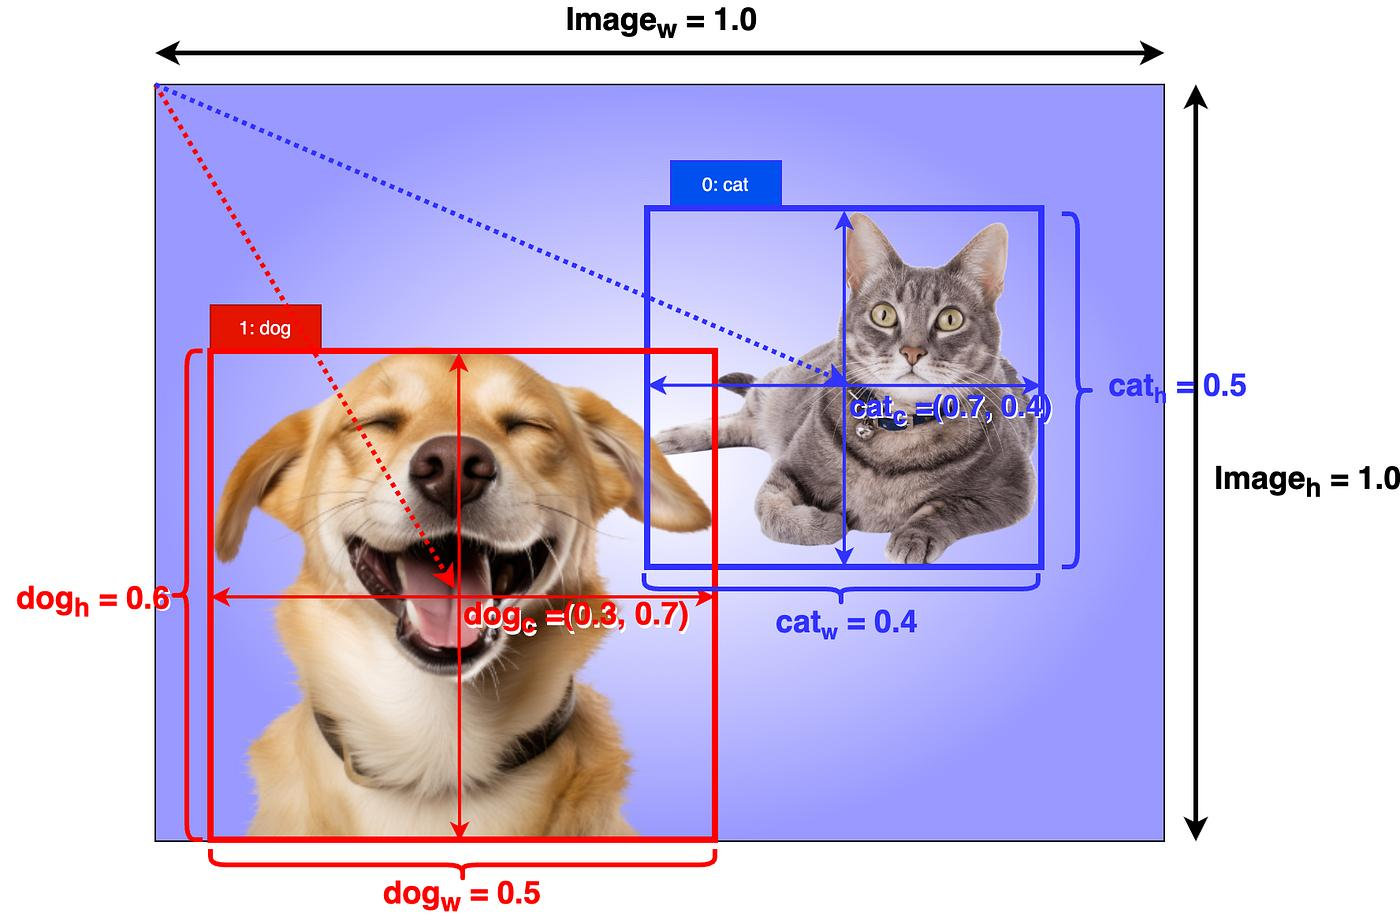
- 객체 탐지 모델은 bounding box의 위치와 크기를 예측하여 이미지 안에서 객체가 어디에 있는지 표시함
- 모델 적용 방식
    - Classification Method : 객체의 종류 예측
    - Regression Head : 객체의 위치 좌표 예측

## 4.3 이미지 캡셔닝
- 이미지의 개념을 자연어 문장으로 표현하는 작업
- 이미지 특징을 추출하는 CNN과 문장을 생성하는 RNN이 함께 사용됨
- 자전거라는 객체를 찾아내는것을 넘어, **사람이 자전거를 타고 있다는 객체 간의 관계와 행동까지 파악하여 문장으로 표현**
- 이미지 캡셔닝 단계
    1. CNN을 이용하여 특징 추출
    2. Attention Network를 이용하여 단어 생성
        - Attention은 문장을 생성할 때 이미지의 모든 영역을 동일하게 고려하지 않고, 현재 생성하려는 단어와 관련된 중요한 영역에 더 높은 가중치를 부여하는 방식
    3. RNN을 이용하여 문장 완성

# 5. RNN
- 순차 데이터: 데이터의 순서가 의미를 갖는 데이터로, 순서를 바꾸면 정보가 달라지는 데이터
- 순차 데이터 분류 
    1. 순서의 기준 : 시간적 순차 데이터/비시간적 순차 데이터(시간외 기준: 위치, 순번)
    2. 자료형 : 수치형/범주형

- 순차 데이터의 경우, 순서를 바꾸면 정보가 달라지기 때문에 기존의 정형 데이터를 기준으로 설계된 모델 이외의 별도의 모델이 필요!<br>**=>RNN**

## 5.1 RNN의 구조와 원리
- 기존신경망과 비교했을 때 가장 큰 차이점은 **은닉층에 순환 구조가 존재하는 것**
- 원리: 매 시점마다 **현재 시점 입력값과 이전 시점 은닉상태**를 이용해 **현재의 은닉상태를 계산**하고 그 결과를 다음 시점으로 넘겨줌
    - 은닉 상태$hₜ$ 계산: 현재 입력 $xₜ$ + 이전 은닉 상태 $hₜ₋₁$ → 새로운 은닉 상태 $hₜ$
    - 출력 계산: 은닉 상태 $hₜ$로 현재 시점의 출력을 만듦

- RNN 아키텍처
    - One to Many : 하나의 입력에서 시퀀스 출력
    - Many to One : 시퀀스 입력에서 하나의 값 출력
    - Many to Many : 시퀀스 입력에서 시퀀스 출력

- 한계점 : RNN은 순전파를 통해 시퀀스를 처리한 뒤, **시간을 거슬러 올라가며 오차를 전파하여 가중치 기울기를 누적 계산함**
    - 기울기 소실 문제로, 가까운 시점은 학습되지만, 먼 과거 시점의 정보는 학습에 거의 반영되지 않게됨
    - 역전파 과정에서 기울기가 과거 시점으로 갈수록 점점 커져 매우 큰 값이 되는 **기울기 폭주** 발생<br>심하면 오차값이 너무 커져 계산이 불가해지고 학습이 중단됨
    - 느린 훈련 시간: RNN은 시점을 하나씩 순서대로만 계산할 수 있어서, 시퀀스가 길수록 학습에 시간이 오래 걸리게 됨

- 위 세 가지 한계점은 결국 시퀀스에서 **관련된 정보가 멀리 떨어져 있을수록, RNN이 그 관계를 기억하고 학습하지 못하는 장기 의존성 문제**로 귀결됨

따라서 등장한 것이 **LSTM 과 GRU!**

# 6. LSTM 과 GRU
- RNN의 한계점을 보완하기위해 **중요한 정보는 오래 기억하고, 불필요한 정보는 잊는 메모리 구조**가 필요
- LSTM(Long Shot term Memory) : 오래 남길 기억과 단기 기억을 나눠서 관리
    - 세 개의 게이트 존재
    1. **Forget Gate**<br>→ 장기 기억에서 더 이상 필요 없는 내용을 삭제
    2. **Input Gate**<br>→ 새로 들어온 정보 중 중요한 것만 장기기억에 저장
    3. **Output Gate**<br>→ 장기기억 중 지금 필요한 부분만 꺼내 단기기억으로 내보냄
- GRU(Gated Recurrent Unit) : 기억을 하나로 통합해서 관리
    - 두 개의 게이트
    1. **Update Gate** → 과거 기억 : 새 정보 = 몇 : 몇 <br>
    → 예) 과거 70 : 새 정보 30으로 섞기<br>
    → LSTM의 Forget Gate + Input Gate를 게이트 하나로 처리
    2. **Reset Gate** → 과거 기억을 얼마나 무시할건지 <br>
    → 새 정보를 해석할 때 과거 기억을 얼마나 참고할지 결정


- 상황별 모델 선택
    - 두 모델은 우열 관계가 아니라 정교함(LSTM) 과 효율(GRU) 사이의 선택
    - 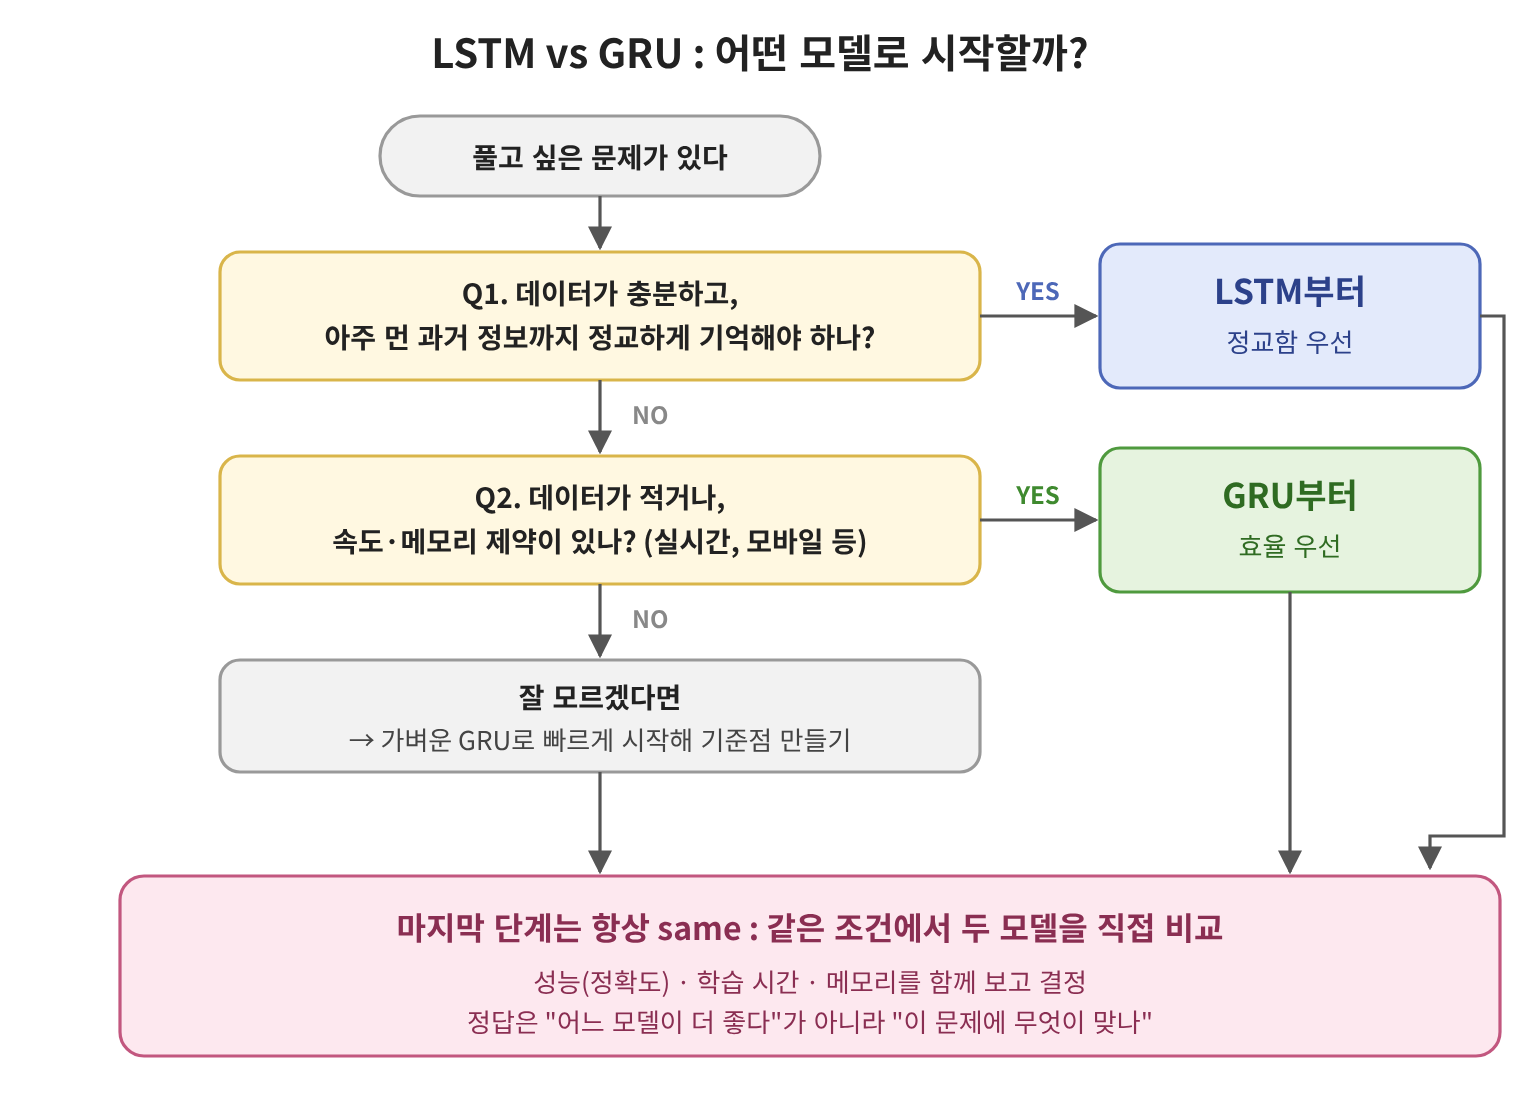

# 7. Seq2Seq
- 개념: 입력 시퀀스를 받아 다른 시퀀스를 출력하는 모델
- **입력과 출력의 길이가 서로 달라도 됨 -> 기존 RNN과 가장 큰 차이**
- 특징 : **인코더(Encoder)와 디코더(Decoder)** 두 개의 모듈로 구성됨
- **인코더** : 입력 문장을 읽고 하나의 **컨텍스트 벡터**로 압축
- **컨텍스트 벡터(Context Vector) :** 인코더와 디코더를 잇는 다리이자 인코더를 거치면서 압축된 정보
- **디코더** : 컨텍스트 벡터를 받아 출력 문장을 한 단어씩 생성

##### 인코더 작동 원리
1. **단어 토큰화** : 입력 문장을 단어 단위로 나눔 → "I", "like", "an", "apple"

2. **임베딩(embedding)** : 각 단어를 컴퓨터가 계산할 수 있는 숫자 벡터로 변환

3. **LSTM 셀에 한 단어씩 입력** : 매 시점 은닉 상태가 다음 시점으로 전달되며 정보가 누적됨

4. **마지막 시점의 은닉 상태** = 문장 전체 정보가 담긴 **컨텍스트 벡터** 
→ 디코더로 전달
##### 디코더 작동 원리
1. 컨텍스트 벡터를 디코더 LSTM의 첫 은닉 상태로 받음

2. 시작 신호 <sos>(start of sequence)를 첫 입력으로 넣음

3. 매 시점 softmax로 다음 단어의 확률을 계산 → 가장 확률이 높은 단어 선택(argmax)

4. 방금 예측한 단어를 다음 시점의 입력으로 다시 넣음

ex) <sos> → "je" → "suis" → "étudiant"

5. 종료 신호 <eos>(end of sequence)가 나오면 생성 종료

##### 컨텍스트 벡터
- 인코더가 입력 문장 전체를 읽고 만든 문장 요약 벡터
- 인코더 LSTM의 마지막 시점 은닉 상태 (LSTM이면 셀 상태도 함께 넘김)
- 인코더와 디코더를 연결하는 유일한 통로

- Seq2Seq의 한계: **병목현상**
    - 인코더가 입력 문장 전체를 **‘고정된 크기의 컨텍스트 벡터 하나’에 압축**하면서 **정보가 좁은 통로에 막혀 손실**되는 현상
    - 5단어든 50단어든 같은 크기(예: 512차원)에 담아야 함 → 긴 문장일수록 정보를 다 담지 못하고 손실되는 정보 발생
    
    - 앞 단어는 여러 시점을 거치며 희미해짐→ 장기 의존성 문제 여전히 존재

**이러한 한계를 해결한 것이 Attention!**